In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, r2_score,root_mean_squared_error)
from pathlib import Path
import matplotlib.pyplot as plt
import sys
sys.path.append('..')
from src.preparacao import carregar_dados

caminho = Path('../data/TESTE_ML_COM_TAXAS_INFRA.csv')
df = carregar_dados(caminho)

display(df)

,cod_municipio,nome_municipio,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,evasao,tx_repet
0,4201273,Arabutã,34.6,41.70,100.00,100.00,71.43,15.1,2056.91,0.0,0.9
1,4201703,Ascurra,41.5,18.45,63.64,54.55,18.18,29.6,1713.62,3.9,4.8
2,4201950,Balneário Arroio do Silva,35.8,44.02,87.50,75.00,37.50,23.3,1530.60,3.0,2.3
3,4202578,Bom Jesus do Oeste,31.6,41.36,75.00,75.00,50.00,8.7,2347.75,1.8,1.8
4,4203154,Calmon,17.4,30.26,62.50,75.00,25.00,22.2,1031.92,6.1,1.5
...,...,...,...,...,...,...,...,...,...,...,...
290,4216800,São José do Cerrito,25.5,58.87,24.14,65.52,10.34,23.9,1223.88,0.3,3.0
291,4217303,Saudades,26.9,34.33,75.00,81.25,31.25,17.6,2154.73,3.5,7.9
292,4218806,Turvo,33.3,34.14,100.00,93.33,0.00,24.3,2009.39,2.6,4.5
293,4219002,Urussanga,25.6,24.52,89.47,73.68,21.05,21.5,1838.88,2.2,6.6


In [ ]:
colunas_ml = ['perc_doc_sobrecarga','taxa_informal','tx_repet','renda_pc',
              'taxa_internet', 'taxa_climatizacao','taxa_lab','media_alunos_por_sala']

x = df[colunas_ml]
y = df['evasao']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

modelo = GradientBoostingRegressor(random_state=42, loss='absolute_error')

parametrod_grid = {
    'n_estimators':     [100, 200, 300],
    'learning_rate':    [0.01, 0.05, 0.1],
    'max_depth':        [2, 3, 4, 7],
    'min_samples_leaf': [5, 10, 20],
    'min_samples_split': [4, 8, 12],
    'max_features':     [None, 'sqrt'],
    'subsample':        [0.7, 0.9, 1.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(estimator=modelo, param_grid=parametrod_grid,
            cv=cv, scoring='neg_mean_absolute_error', verbose=1, n_jobs=-1)
100
grid_search.fit(x_treino, y_treino)

print("Melhores Hiperparâmetros encontradas:")
print(grid_search.best_params_)

print(f"\nMelhor pontuação média (MAE na validação cruzada): {grid_search.best_score_:.4f}")

df_resultados = pd.DataFrame(grid_search.cv_results_)

colunas_parametros = [col for col in df_resultados.columns if col.startswith('param_')]

colunas_finais = colunas_parametros + ['mean_test_score', 'rank_test_score']

display(df_resultados[colunas_finais].sort_values(by='rank_test_score'))

Fitting 5 folds for each of 1944 candidates, totalling 9720 fits
Melhores Hiperparâmetros encontradas:
{'learning_rate': 0.01, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 20, 'min_samples_split': 4, 'n_estimators': 200, 'subsample': 0.7}

Melhor pontuação média (MAE na validação cruzada): -1.5517


,param_learning_rate,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,param_subsample,mean_test_score,rank_test_score
147,0.01,2,sqrt,20,8,200,0.7,-1.551693,1
156,0.01,2,sqrt,20,12,200,0.7,-1.551693,1
138,0.01,2,sqrt,20,4,200,0.7,-1.551693,1
27,0.01,2,None,10,4,100,0.7,-1.553909,4
36,0.01,2,None,10,8,100,0.7,-1.553909,4
...,...,...,...,...,...,...,...,...,...
1509,0.10,3,None,10,12,300,0.7,-1.756576,1939
1500,0.10,3,None,10,8,300,0.7,-1.756576,1939
1419,0.10,2,sqrt,10,8,300,0.7,-1.770884,1942
1428,0.10,2,sqrt,10,12,300,0.7,-1.770884,1942


In [ ]:
from sklearn.metrics import root_mean_squared_error

melhor_modelo = grid_search.best_estimator_

melhor_modelo.fit(x_treino, y_treino)

previsoes = melhor_modelo.predict(x_teste)

mae = mean_absolute_error(y_teste, previsoes)
r2 = r2_score(y_teste, previsoes)
rmse = root_mean_squared_error(y_teste, previsoes)

print(f"\nMAE final: {mae:.4f}")
print(f"\nR2 final: {r2:.4f}")
print(f"\nRMSE final: {rmse:.4f}")


MAE final: 1.4684

R2 final: 0.0910

RMSE final: 1.9446


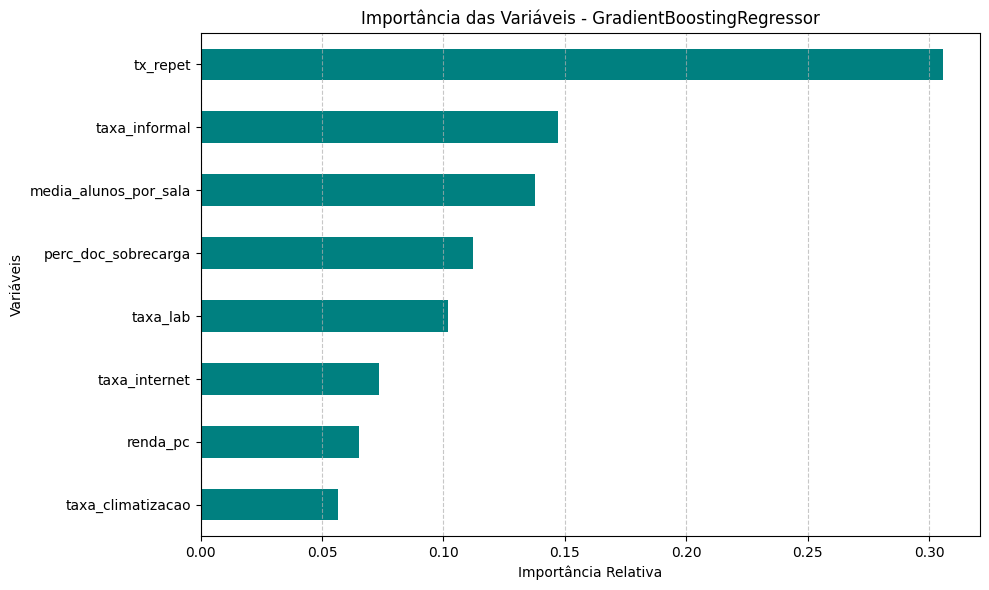

In [9]:

importancias = melhor_modelo.feature_importances_

importancias_df = pd.Series(importancias, index=x_treino.columns).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
importancias_df.plot(kind='barh', color='teal')
plt.title('Importância das Variáveis - GradientBoostingRegressor')
plt.xlabel('Importância Relativa')
plt.ylabel('Variáveis')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()